In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("../smart_campus_facility_dataset.csv")

In [4]:
df.head()
# df.shape
# df.columns
# df.info()

,Complaint_ID,User_Type,User_ID,Block_No,Floor,Room_No,Facility_Type,Issue_Type,Complaint_Date,Day_of_Week,Complaint_Time,Footfall,Previous_Complaints,Severity,Resolution_Time_Hours,Photo_Available,Complaint_DateTime
0,CMP00001,Student,12447848,2,6,602,Furniture,Damaged Furniture,2025-01-01,Wednesday,08:21,95,0,Low,13.4,Yes,2025-01-01 08:21:00
1,CMP00002,Student,12485420,21,2,203,Water Cooler,No Water,2025-01-01,Wednesday,09:27,293,0,Medium,9.5,Yes,2025-01-01 09:27:00
2,CMP00003,Student,12464762,34,5,507,Projector,Blurry Display,2025-01-01,Wednesday,09:45,33,0,Low,18.3,Yes,2025-01-01 09:45:00
3,CMP00004,Student,12429363,13,6,604,Water Cooler,Not Working,2025-01-01,Wednesday,09:59,452,0,Low,16.1,No,2025-01-01 09:59:00
4,CMP00005,Student,12406716,21,2,203,Water Cooler,Water Quality,2025-01-01,Wednesday,10:41,552,1,Low,14.1,No,2025-01-01 10:41:00


In [5]:
df.isnull().sum()
df.duplicated().sum()

np.int64(0)

In [6]:
df.nunique()

Complaint_ID             10000
User_Type                    2
User_ID                   9509
Block_No                    50
Floor                        7
Room_No                     63
Facility_Type               11
Issue_Type                  34
Complaint_Date             609
Day_of_Week                  7
Complaint_Time             720
Footfall                   671
Previous_Complaints        411
Severity                     4
Resolution_Time_Hours      236
Photo_Available              2
Complaint_DateTime        9897
dtype: int64

In [7]:
facility_counts = df["Facility_Type"].value_counts()

print(facility_counts)

Facility_Type
Water Cooler    1062
Garbage         1027
AC              1024
Washroom        1019
Lift            1004
Projector        999
Electrical       963
WiFi             948
Furniture        672
Classroom        661
Lighting         621
Name: count, dtype: int64


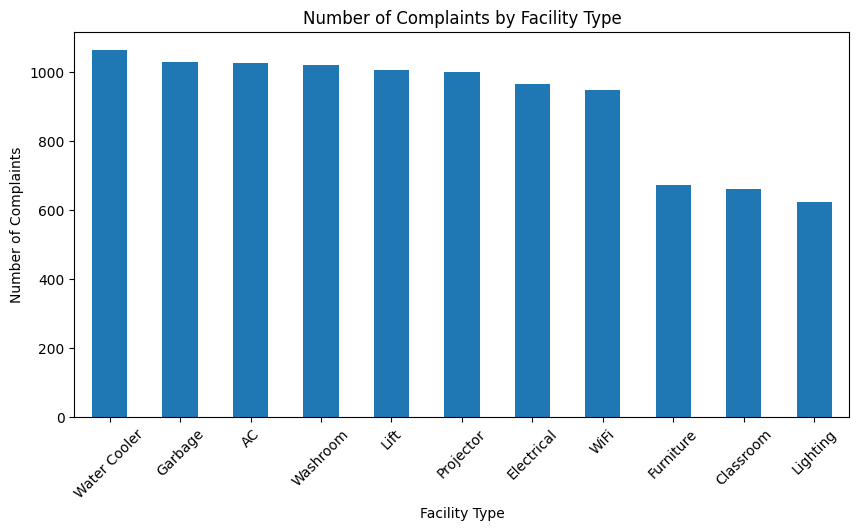

In [8]:
facility_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Number of Complaints by Facility Type")
plt.xlabel("Facility Type")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.show()

In [9]:
severity_counts = df["Severity"].value_counts()

print(severity_counts)

Severity
Medium      4254
Low         3278
High        2069
Critical     399
Name: count, dtype: int64


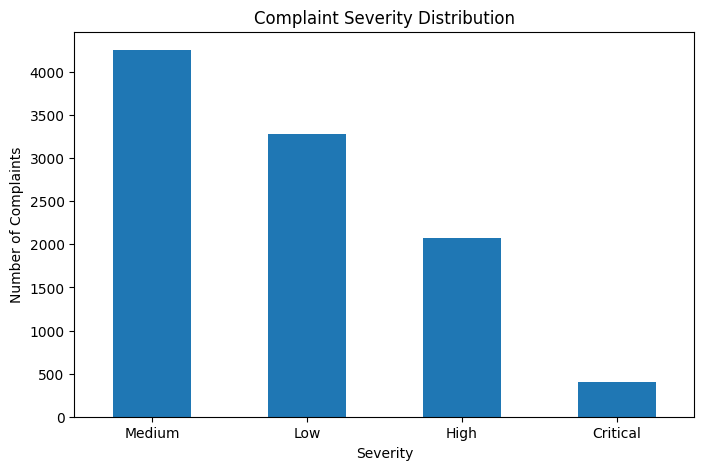

In [10]:
severity_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Complaint Severity Distribution")
plt.xlabel("Severity")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=0)
plt.show()

In [11]:
issue_counts = df["Issue_Type"].value_counts()

print(issue_counts)

Issue_Type
Not Working               787
No Water                  661
Water Leakage             611
Bin Overflow              539
Not Cooling               458
Power Failure             447
No Display                444
Cleanliness               443
Frequent Disconnection    413
Unusual Noise             367
Bad Odour                 252
Waste Not Collected       236
Broken Chair              230
Damaged Furniture         229
Fan Not Working           224
General Maintenance       219
Electrical Fault          219
Damaged Board             218
Broken Desk               213
Blurry Display            210
Stuck                     210
Water Quality             202
Flickering                202
Light Not Working         200
Socket Problem            196
Slow Speed                190
Door Problem              186
Fixture Damage            184
HDMI Problem              182
No Connection             180
Switch Problem            178
Authentication Problem    165
Power Issue               163

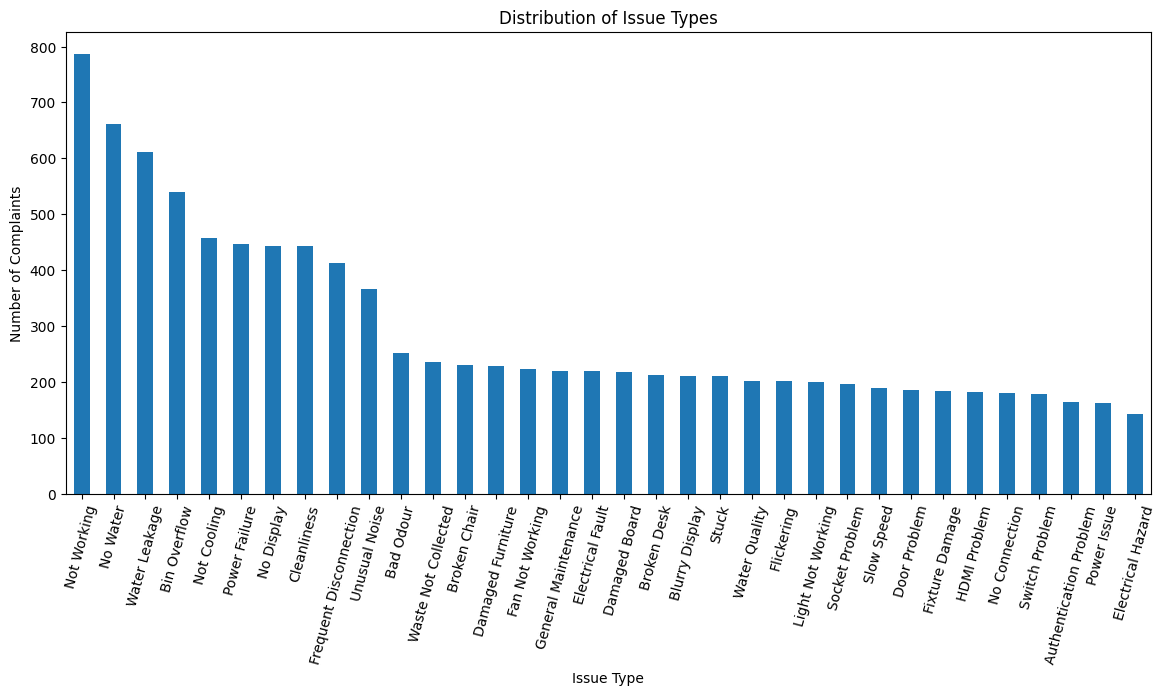

In [12]:
issue_counts.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Distribution of Issue Types")
plt.xlabel("Issue Type")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=75)
plt.show()

In [13]:
facility_issue_counts = pd.crosstab(
    df["Facility_Type"],
    df["Issue_Type"]
)

facility_issue_counts

Issue_Type,Authentication Problem,Bad Odour,Bin Overflow,Blurry Display,Broken Chair,Broken Desk,Cleanliness,Damaged Board,Damaged Furniture,Door Problem,...,Power Failure,Power Issue,Slow Speed,Socket Problem,Stuck,Switch Problem,Unusual Noise,Waste Not Collected,Water Leakage,Water Quality
Facility_Type,,,,,,,,,,,,,,,,,,,,,
AC,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,178,0,194,0
Classroom,0,0,0,0,0,0,0,218,0,0,...,0,0,0,0,0,0,0,0,0,0
Electrical,0,0,0,0,0,0,0,0,0,0,...,447,0,0,196,0,178,0,0,0,0
Furniture,0,0,0,0,230,213,0,0,229,0,...,0,0,0,0,0,0,0,0,0,0
Garbage,0,252,539,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,236,0,0
Lift,0,0,0,0,0,0,0,0,0,186,...,0,0,0,0,210,0,189,0,0,0
Lighting,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Projector,0,0,0,210,0,0,0,0,0,0,...,0,163,0,0,0,0,0,0,0,0
Washroom,0,0,0,0,0,0,443,0,0,0,...,0,0,0,0,0,0,0,0,207,0


In [14]:
for facility in df["Facility_Type"].unique():

    print("\n", facility)

    print(
        df[df["Facility_Type"] == facility]["Issue_Type"]
        .value_counts()
    )


 Furniture
Issue_Type
Broken Chair         230
Damaged Furniture    229
Broken Desk          213
Name: count, dtype: int64

 Water Cooler
Issue_Type
No Water         476
Water Leakage    210
Water Quality    202
Not Working      174
Name: count, dtype: int64

 Projector
Issue_Type
No Display        444
Blurry Display    210
HDMI Problem      182
Power Issue       163
Name: count, dtype: int64

 AC
Issue_Type
Not Cooling      458
Not Working      194
Water Leakage    194
Unusual Noise    178
Name: count, dtype: int64

 Electrical
Issue_Type
Power Failure        447
Socket Problem       196
Switch Problem       178
Electrical Hazard    142
Name: count, dtype: int64

 Classroom
Issue_Type
Fan Not Working        224
General Maintenance    219
Damaged Board          218
Name: count, dtype: int64

 WiFi
Issue_Type
Frequent Disconnection    413
Slow Speed                190
No Connection             180
Authentication Problem    165
Name: count, dtype: int64

 Garbage
Issue_Type
Bin Overflow

In [15]:
location_counts = (
    df.groupby(
        ["Block_No", "Floor", "Room_No", "Facility_Type"]
    )
    .size()
    .reset_index(name="Complaint_Count")
)

location_counts.head()

,Block_No,Floor,Room_No,Facility_Type,Complaint_Count
0,1,1,101,Washroom,1
1,1,1,102,Projector,1
2,1,1,103,Lift,1
3,1,1,103,Washroom,1
4,1,1,103,Water Cooler,1


In [16]:
high_risk_locations = location_counts.sort_values(
    by="Complaint_Count",
    ascending=False
)

high_risk_locations.head(10)

,Block_No,Floor,Room_No,Facility_Type,Complaint_Count
2561,21,2,203,Water Cooler,411
5583,45,1,102,Garbage,402
4228,34,5,507,Projector,388
4968,40,2,204,Lift,382
3562,29,3,307,Electrical,377
2128,17,6,605,AC,367
974,8,4,404,WiFi,342
1436,12,3,305,Washroom,329
1505,12,7,703,AC,3
2880,23,7,702,Lift,3


In [17]:
severity_weights = {
    "Low": 1,
    "Medium": 2,
    "High": 3,
    "Critical": 4
}

df["Severity_Score"] = df["Severity"].map(severity_weights)


df[
    ["Severity", "Severity_Score"]
].head(20)

,Severity,Severity_Score
0,Low,1
1,Medium,2
2,Low,1
3,Low,1
4,Low,1
5,Low,1
6,High,3
7,Medium,2
8,Medium,2
9,Medium,2


In [18]:
location_risk = (
    df.groupby(
        ["Block_No", "Floor", "Room_No", "Facility_Type"]
    )
    .agg(
        Complaint_Count=("Complaint_ID", "count"),
        Average_Severity=("Severity_Score", "mean"),
        Max_Severity=("Severity_Score", "max")
    )
    .reset_index()
)


location_risk.sort_values(
    by="Complaint_Count",
    ascending=False
).head(10)

,Block_No,Floor,Room_No,Facility_Type,Complaint_Count,Average_Severity,Max_Severity
2561,21,2,203,Water Cooler,411,2.695864,3
5583,45,1,102,Garbage,402,2.696517,3
4228,34,5,507,Projector,388,2.515464,3
4968,40,2,204,Lift,382,2.670157,4
3562,29,3,307,Electrical,377,3.381963,4
2128,17,6,605,AC,367,2.504087,3
974,8,4,404,WiFi,342,2.628655,3
1436,12,3,305,Washroom,329,2.729483,3
1505,12,7,703,AC,3,1.333333,2
2880,23,7,702,Lift,3,2.000000,3


In [19]:
# Step 1: Normalize complaint frequency
location_risk["Frequency_Score"] = (
    location_risk["Complaint_Count"]
    / location_risk["Complaint_Count"].max()
)

# Step 2: Normalize average severity
location_risk["Severity_Normalized"] = (
    location_risk["Average_Severity"]
    / 4
)

# Step 3: Calculate final risk score
location_risk["Risk_Score"] = (
    0.5 * location_risk["Frequency_Score"]
    + 0.5 * location_risk["Severity_Normalized"]
)

In [20]:
location_risk.sort_values(
    by="Risk_Score",
    ascending=False
).head(10)

,Block_No,Floor,Room_No,Facility_Type,Complaint_Count,Average_Severity,Max_Severity,Frequency_Score,Severity_Normalized,Risk_Score
3562,29,3,307,Electrical,377,3.381963,4,0.917275,0.845491,0.881383
2561,21,2,203,Water Cooler,411,2.695864,3,1.000000,0.673966,0.836983
5583,45,1,102,Garbage,402,2.696517,3,0.978102,0.674129,0.826116
4968,40,2,204,Lift,382,2.670157,4,0.929440,0.667539,0.798490
4228,34,5,507,Projector,388,2.515464,3,0.944039,0.628866,0.786452
2128,17,6,605,AC,367,2.504087,3,0.892944,0.626022,0.759483
974,8,4,404,WiFi,342,2.628655,3,0.832117,0.657164,0.744640
1436,12,3,305,Washroom,329,2.729483,3,0.800487,0.682371,0.741429
2584,21,3,307,Electrical,2,4.000000,4,0.004866,1.000000,0.502433
223,2,7,704,Lift,2,4.000000,4,0.004866,1.000000,0.502433


In [21]:
recurring_locations = location_risk[
    location_risk["Complaint_Count"] >= 5
]

recurring_locations.sort_values(
    by="Risk_Score",
    ascending=False
).head(10)

,Block_No,Floor,Room_No,Facility_Type,Complaint_Count,Average_Severity,Max_Severity,Frequency_Score,Severity_Normalized,Risk_Score
3562,29,3,307,Electrical,377,3.381963,4,0.917275,0.845491,0.881383
2561,21,2,203,Water Cooler,411,2.695864,3,1.000000,0.673966,0.836983
5583,45,1,102,Garbage,402,2.696517,3,0.978102,0.674129,0.826116
4968,40,2,204,Lift,382,2.670157,4,0.929440,0.667539,0.798490
4228,34,5,507,Projector,388,2.515464,3,0.944039,0.628866,0.786452
2128,17,6,605,AC,367,2.504087,3,0.892944,0.626022,0.759483
974,8,4,404,WiFi,342,2.628655,3,0.832117,0.657164,0.744640
1436,12,3,305,Washroom,329,2.729483,3,0.800487,0.682371,0.741429


In [22]:
df["Complaint_DateTime"] = pd.to_datetime(
    df["Complaint_DateTime"]
)

df["Month"] = df["Complaint_DateTime"].dt.month

monthly_complaints = (
    df["Month"]
    .value_counts()
    .sort_index()
)

monthly_complaints

Month
1      989
2      928
3     1093
4      993
5     1046
6      955
7     1005
8     1062
9      501
10     507
11     473
12     448
Name: count, dtype: int64

In [25]:
df["Year_Month"] = (
    df["Complaint_DateTime"]
    .dt.to_period("M")
)

monthly_trend = (
    df["Year_Month"]
    .value_counts()
    .sort_index()
)

monthly_trend

Year_Month
2025-01    474
2025-02    460
2025-03    536
2025-04    471
2025-05    510
2025-06    481
2025-07    501
2025-08    538
2025-09    484
2025-10    507
2025-11    473
2025-12    448
2026-01    515
2026-02    468
2026-03    557
2026-04    522
2026-05    536
2026-06    474
2026-07    504
2026-08    524
2026-09     17
Freq: M, Name: count, dtype: int64

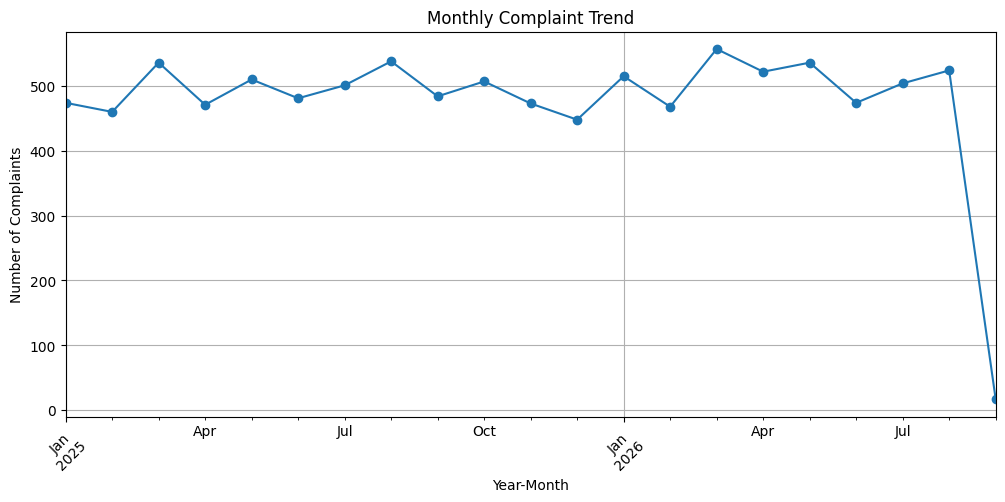

In [26]:
monthly_trend.plot(
    kind="line",
    figsize=(12, 5),
    marker="o"
)

plt.title("Monthly Complaint Trend")
plt.xlabel("Year-Month")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.grid()
plt.show()

In [27]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_counts = (
    df["Day_of_Week"]
    .value_counts()
    .reindex(day_order)
)

day_counts

Day_of_Week
Monday       1471
Tuesday      1430
Wednesday    1412
Thursday     1409
Friday       1423
Saturday     1400
Sunday       1455
Name: count, dtype: int64

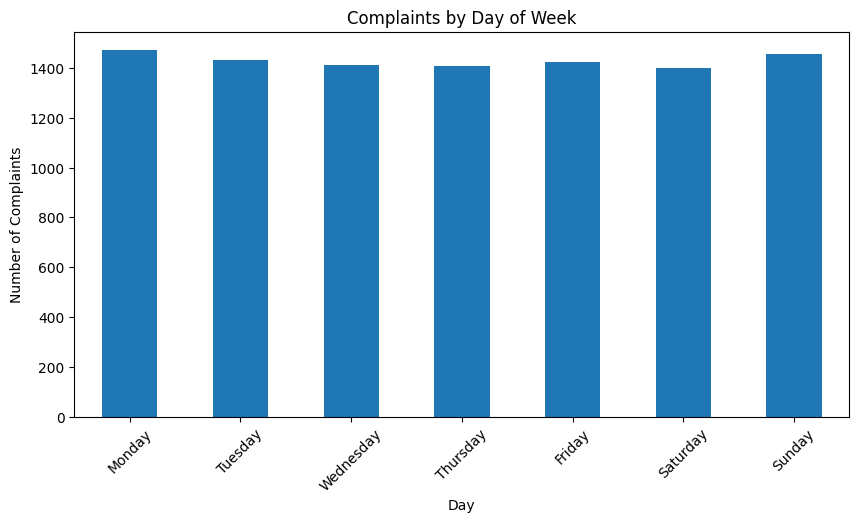

In [28]:
day_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Complaints by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.show()

In [29]:
df["Hour"] = df["Complaint_DateTime"].dt.hour

df[
    ["Complaint_DateTime", "Hour"]
].head()

,Complaint_DateTime,Hour
0,2025-01-01 08:21:00,8
1,2025-01-01 09:27:00,9
2,2025-01-01 09:45:00,9
3,2025-01-01 09:59:00,9
4,2025-01-01 10:41:00,10


In [32]:


df["Hour"] = df["Complaint_DateTime"].dt.strftime("%I %p")

hour_order = [
    "08 AM", "09 AM", "10 AM", "11 AM",
    "12 PM", "01 PM", "02 PM", "03 PM",
    "04 PM", "05 PM", "06 PM", "07 PM"
]

hourly_counts = (
    df["Hour"]
    .value_counts()
    .reindex(hour_order)
)

hourly_counts

Hour
08 AM    825
09 AM    842
10 AM    862
11 AM    812
12 PM    822
01 PM    825
02 PM    900
03 PM    809
04 PM    783
05 PM    879
06 PM    808
07 PM    833
Name: count, dtype: int64

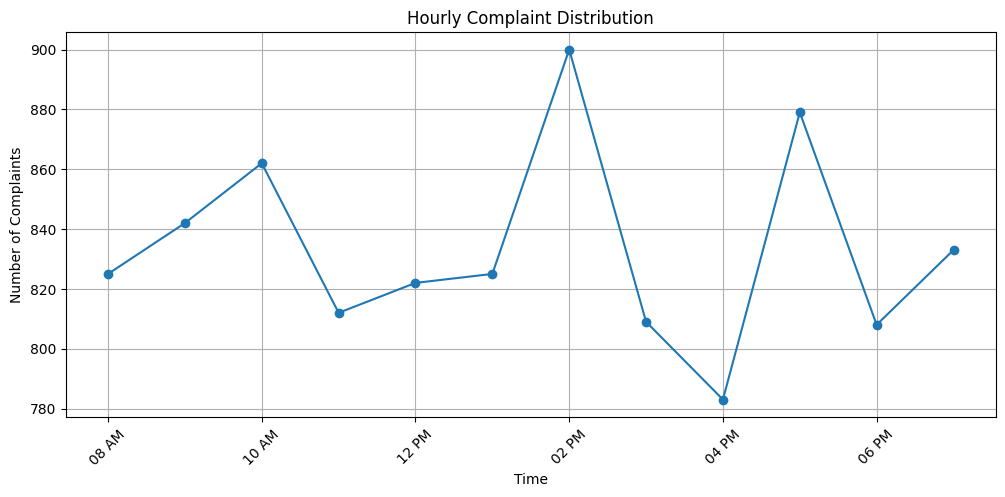

In [34]:
hourly_counts.plot(
    kind="line",
    marker="o",
    figsize=(12, 5)
)

plt.title("Hourly Complaint Distribution")
plt.xlabel("Time")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.grid()
plt.show()

In [35]:
df["Footfall"].describe()




count    10000.00000
mean       303.99000
std        192.71821
min         30.00000
25%        120.00000
50%        288.00000
75%        473.00000
max        700.00000
Name: Footfall, dtype: float64

In [36]:
facility_footfall = (
    df.groupby("Facility_Type")["Footfall"]
    .mean()
    .sort_values(ascending=False)
)

facility_footfall

Facility_Type
Washroom        460.167812
Garbage         453.194742
Water Cooler    452.053672
Lift            379.270916
Lighting        374.586151
WiFi            374.050633
Electrical      370.916926
Furniture        89.967262
Classroom        89.547655
AC               89.428711
Projector        89.143143
Name: Footfall, dtype: float64

In [37]:
footfall_by_severity = (
    df.groupby("Severity")["Footfall"]
    .mean()
    .reindex(["Low", "Medium", "High", "Critical"])
)

footfall_by_severity

Severity
Low         287.518914
Medium      276.354020
High        375.333494
Critical    364.005013
Name: Footfall, dtype: float64

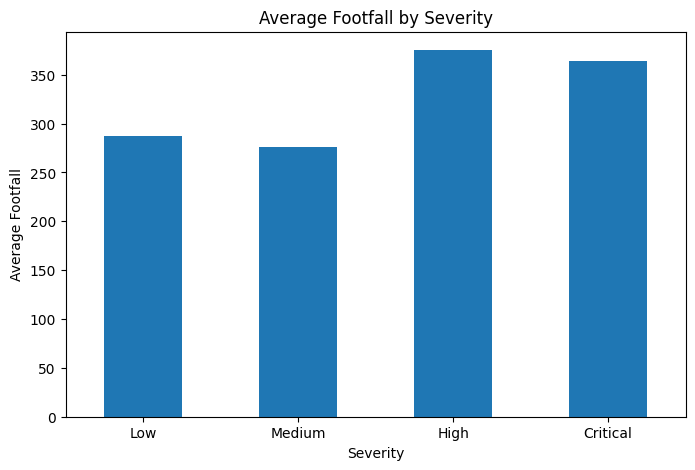

In [38]:
footfall_by_severity.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Footfall by Severity")
plt.xlabel("Severity")
plt.ylabel("Average Footfall")
plt.xticks(rotation=0)
plt.show()

In [39]:
previous_by_severity = (
    df.groupby("Severity")["Previous_Complaints"]
    .mean()
    .reindex(["Low", "Medium", "High", "Critical"])
)

previous_by_severity

Severity
Low           0.112569
Medium       41.857311
High        171.498308
Critical     76.325815
Name: Previous_Complaints, dtype: float64

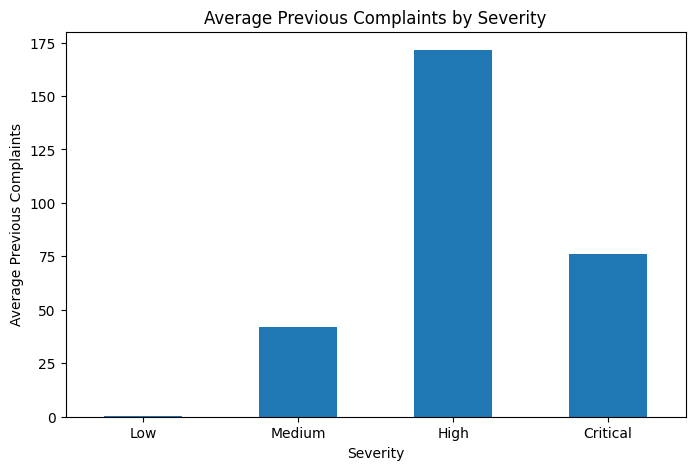

In [40]:
previous_by_severity.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Previous Complaints by Severity")
plt.xlabel("Severity")
plt.ylabel("Average Previous Complaints")
plt.xticks(rotation=0)
plt.show()

In [41]:
resolution_by_severity = (
    df.groupby("Severity")["Resolution_Time_Hours"]
    .mean()
    .reindex(["Low", "Medium", "High", "Critical"])
)

resolution_by_severity

Severity
Low         16.238896
Medium       8.008463
High         3.533639
Critical     1.219549
Name: Resolution_Time_Hours, dtype: float64

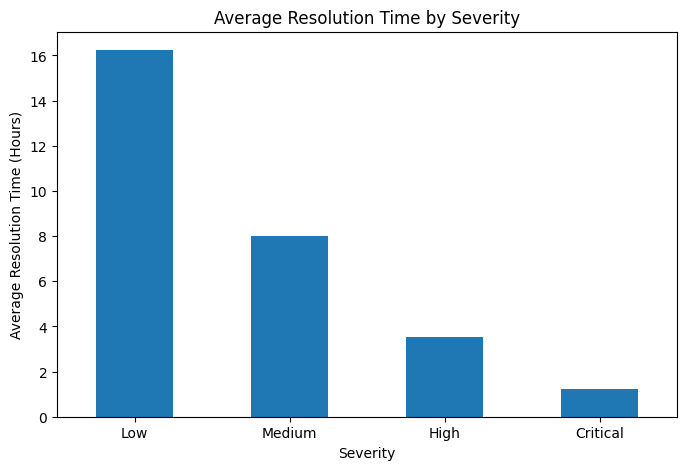

In [42]:
resolution_by_severity.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Resolution Time by Severity")
plt.xlabel("Severity")
plt.ylabel("Average Resolution Time (Hours)")
plt.xticks(rotation=0)
plt.show()